In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from scipy import stats

In [2]:
df = pd.read_csv('../data/processed/train.csv')

# Nettoyer les noms de colonnes
df.columns = df.columns.str.strip()

# Afficher les colonnes
print(df.columns)

Index(['text', 'label', 'score', 'hotel'], dtype='object')


In [3]:
# Vérification des colonnes nécessaires
print(df[['hotel', 'score']].head(10))
print(f"Nombre d'hôtels uniques : {df['hotel'].nunique()}")
print(f"Nombre d'avis total     : {len(df)}")

                                hotel  score
0                       Hilton Vienna   10.0
1             Melia White House Hotel    9.2
2   DoubleTree By Hilton London Excel   10.0
3              H10 Metropolitan 4 Sup    9.2
4     Eurostars Grand Marina Hotel GL   10.0
5                    Acevi Villarroel    8.3
6               Hilton London Olympia    9.2
7  H tel Le Bellechasse Saint Germain    8.8
8                Amadi Panorama Hotel   10.0
9       The Cumberland A Guoman Hotel    8.3
Nombre d'hôtels uniques : 1492
Nombre d'avis total     : 361016


### Agrégation des scores par hôtel

In [4]:
# Statistiques de base par hôtel
hotel_stats = df.groupby('hotel').agg(
    nb_avis        = ('score', 'count'),
    score_moyen    = ('score', 'mean'),
    score_median   = ('score', 'median'),
    score_std      = ('score', 'std'),
    score_min      = ('score', 'min'),
    score_max      = ('score', 'max'),
).reset_index()

hotel_stats['score_std'] = hotel_stats['score_std'].fillna(0)

print(hotel_stats.sort_values('score_moyen', ascending=False).head(10))

                                    hotel  nb_avis  score_moyen  score_median  \
3                                      41       62     9.751613          10.0   
472   H tel de La Tamise Esprit de France       40     9.730000          10.0   
895                 Le Narcisse Blanc Spa       41     9.724390          10.0   
598                     Hotel Casa Camper      216     9.708333          10.0   
732             Hotel Plaza Athenee Paris       23     9.678261          10.0   
628                   Hotel Eiffel Blomet       11     9.672727          10.0   
1202                           Ritz Paris       21     9.671429          10.0   
481                 H10 Casa Mimosa 4 Sup       78     9.639744           9.6   
771                      Hotel The Serras      148     9.630405          10.0   
499                       Haymarket Hotel       84     9.615476          10.0   

      score_std  score_min  score_max  
3      0.527829        6.7       10.0  
472    0.355326        8.8  

### Score pondéré (Bayesian Average)

In [5]:
def bayesian_average(nb_avis, score_moyen, C, m):

    return (nb_avis / (nb_avis + C)) * score_moyen + (C / (nb_avis + C)) * m

# Calcul des paramètres globaux
m = df['score'].mean()           # moyenne globale : ex. 8.4
C = hotel_stats['nb_avis'].quantile(0.5)  # seuil : médiane du nb d'avis

print(f"Moyenne globale (m)  : {m:.2f}")
print(f"Seuil d'avis   (C)  : {C:.0f}")

# Application à chaque hôtel
hotel_stats['score_bayes'] = hotel_stats.apply(
    lambda row: bayesian_average(row['nb_avis'], row['score_moyen'], C, m),
    axis=1
)

# Classement final
hotel_stats = hotel_stats.sort_values('score_bayes', ascending=False).reset_index(drop=True)
hotel_stats['rang_ratings'] = hotel_stats.index + 1

print("\nTop 10 hôtels (système ratings) :")
print(hotel_stats[['rang_ratings', 'hotel', 'nb_avis',
                    'score_moyen', 'score_bayes']].head(10).to_string(index=False))

Moyenne globale (m)  : 8.40
Seuil d'avis   (C)  : 134

Top 10 hôtels (système ratings) :
 rang_ratings                                hotel  nb_avis  score_moyen  score_bayes
            1       Intercontinental London The O2     1809     9.459315     9.385920
            2 Shangri La Hotel at The Shard London      758     9.360818     9.215743
            3             Amba Hotel Charing Cross      552     9.406341     9.208808
            4                    Hotel Casa Camper      216     9.708333     9.205550
            5                          Hotel Berna      735     9.353197     9.205458
            6                       Hotel Esther a     1321     9.271537     9.190820
            7                   Olivia Plaza Hotel      557     9.373429     9.183709
            8              Apex Temple Court Hotel      737     9.291180     9.153321
            9                  Olivia Balmes Hotel      358     9.426536     9.145615
           10               Catalonia Square 4 Sup 

###  Fonction de recommandation

In [6]:
def recommander_hotels_ratings(hotel_stats, n=5, nb_avis_min=10,
                                ville=None, score_min=None):

    res = hotel_stats.copy()

    # Filtres optionnels
    res = res[res['nb_avis'] >= nb_avis_min]

    if ville and 'ville' in res.columns:
        res = res[res['ville'].str.lower() == ville.lower()]

    if score_min:
        res = res[res['score_bayes'] >= score_min]

    top = res.nlargest(n, 'score_bayes')[
        ['hotel', 'nb_avis', 'score_moyen', 'score_bayes', 'rang_ratings']
    ].reset_index(drop=True)

    top.index += 1  # rang affiché à partir de 1
    return top


# Exemple d'utilisation
print("=== Top 5 recommandations (système ratings) ===\n")
recommandations = recommander_hotels_ratings(hotel_stats, n=5, nb_avis_min=50)
print(recommandations.to_string())

=== Top 5 recommandations (système ratings) ===

                                  hotel  nb_avis  score_moyen  score_bayes  rang_ratings
1        Intercontinental London The O2     1809     9.459315     9.385920             1
2  Shangri La Hotel at The Shard London      758     9.360818     9.215743             2
3              Amba Hotel Charing Cross      552     9.406341     9.208808             3
4                     Hotel Casa Camper      216     9.708333     9.205550             4
5                           Hotel Berna      735     9.353197     9.205458             5


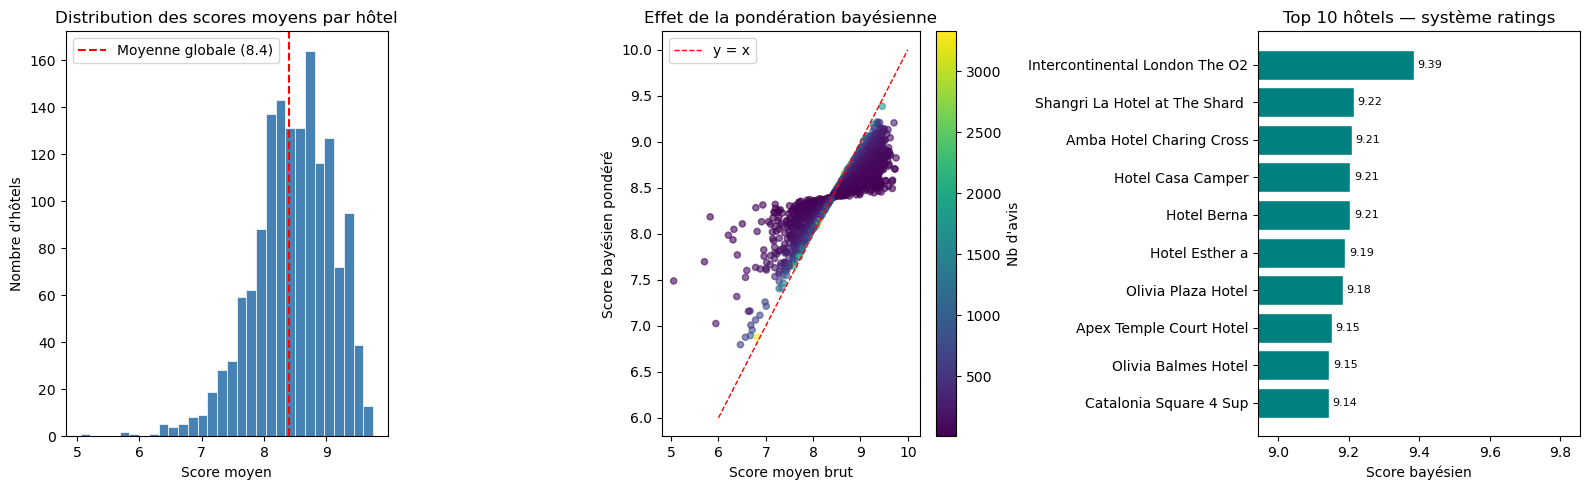

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# --- Graphique 1 : Distribution des scores moyens ---
ax1 = axes[0]
ax1.hist(hotel_stats['score_moyen'], bins=30, color='steelblue',
         edgecolor='white', linewidth=0.5)
ax1.axvline(m, color='red', linestyle='--', linewidth=1.5, label=f'Moyenne globale ({m:.1f})')
ax1.set_title("Distribution des scores moyens par hôtel")
ax1.set_xlabel("Score moyen")
ax1.set_ylabel("Nombre d'hôtels")
ax1.legend()

# --- Graphique 2 : Score moyen vs Score bayésien ---
ax2 = axes[1]
ax2.scatter(hotel_stats['score_moyen'], hotel_stats['score_bayes'],
            c=hotel_stats['nb_avis'], cmap='viridis',
            alpha=0.6, s=20)
ax2.plot([6, 10], [6, 10], 'r--', linewidth=1, label='y = x')
ax2.set_xlabel("Score moyen brut")
ax2.set_ylabel("Score bayésien pondéré")
ax2.set_title("Effet de la pondération bayésienne")
ax2.legend()
sm = plt.cm.ScalarMappable(cmap='viridis',
     norm=plt.Normalize(hotel_stats['nb_avis'].min(),
                        hotel_stats['nb_avis'].max()))
plt.colorbar(sm, ax=ax2, label="Nb d'avis")

# --- Graphique 3 : Top 10 hôtels ---
ax3 = axes[2]
top10 = hotel_stats.head(10).copy()
# Noms raccourcis pour la lisibilité
top10['nom_court'] = top10['hotel'].str[:30]
bars = ax3.barh(top10['nom_court'][::-1], top10['score_bayes'][::-1],
                color='teal', edgecolor='white')
ax3.set_xlabel("Score bayésien")
ax3.set_title("Top 10 hôtels — système ratings")
ax3.set_xlim(left=top10['score_bayes'].min() - 0.2)
for bar, score in zip(bars, top10['score_bayes'][::-1]):
    ax3.text(bar.get_width() + 0.01, bar.get_y() + bar.get_height()/2,
             f'{score:.2f}', va='center', fontsize=8)

plt.tight_layout()
plt.savefig('../results/visualizations/recommandation_ratings.png', dpi=150, bbox_inches='tight')
plt.show()

In [8]:
# Corrélation entre classement par score brut vs score bayésien
hotel_stats['rang_brut']   = hotel_stats['score_moyen'].rank(ascending=False)
hotel_stats['rang_bayes']  = hotel_stats['score_bayes'].rank(ascending=False)

corr, pval = stats.spearmanr(hotel_stats['rang_brut'], hotel_stats['rang_bayes'])
print(f"Corrélation de Spearman (brut vs bayésien) : {corr:.3f}  (p={pval:.4f})")

# Hôtels dont le rang change le plus entre les deux méthodes
hotel_stats['diff_rang'] = (hotel_stats['rang_brut'] - hotel_stats['rang_bayes']).abs()

print("\nHôtels les plus affectés par la pondération bayésienne :")
print(hotel_stats.nlargest(5, 'diff_rang')[
    ['hotel', 'nb_avis', 'score_moyen', 'score_bayes', 'diff_rang']
].to_string(index=False))

# Sauvegarde pour la comparaison avec le système sentiments (étape suivante)
hotel_stats.to_csv('../results/hotel_stats_ratings.csv', index=False)
print("\nFichier sauvegardé : results/hotel_stats_ratings.csv")

Corrélation de Spearman (brut vs bayésien) : 0.946  (p=0.0000)

Hôtels les plus affectés par la pondération bayésienne :
                                 hotel  nb_avis  score_moyen  score_bayes  diff_rang
Renaissance Paris Republique Hotel Spa        8     9.437500     8.453821      663.0
                   Hotel Eiffel Blomet       11     9.672727     8.492018      635.0
                 Splendide Royal Paris       13     9.515385     8.494167      605.0
                Palais Coburg Residenz       10     9.380000     8.463490      596.0
                         Drawing Hotel        8     9.287500     8.445371      595.0

Fichier sauvegardé : results/hotel_stats_ratings.csv
